# NeuroLink 4.0 — Multi-Stream Deep Behavioral Baseline Engine
### *15-Feature · Shared Encoder · 3 Decoder Heads · 90-Day Forecasting · DP-SGD*

---

| | |
|---|---|
| **Series** | NeuroLink V1 → V2 → V3 → **V4.0** |
| **Dataset** | 50,040 keybr.com lessons · Dec 2024 – Jul 2026 |
| **Architecture** | Shared 15→32→16→10 encoder + Speed/Accuracy/Motor decoder heads |
| **Privacy** | DP-SGD (Opacus) · ε≤10.0, δ=1e-5 |
| **New in V4** | Multi-scale LDI (3 streams) · 90-day WPM forecasting · 3 new features |
| **New features** | miss_ratio_top3 · error_rate_trend · speed_dispersion |
| **Dropped** | lesson_dur_z · active_char_frac · practice_gap (low R², near-constant) |

In [ ]:
import json, numpy as np, pandas as pd

CODEPOINT_MAP = {32: 'space', **{ord(c): c for c in 'abcdefghijklmnopqrstuvwxyz'}}
ALL_CHARS = ['space'] + list('abcdefghijklmnopqrstuvwxyz')

with open('typing-data.json', 'r') as f:
    raw = json.load(f)

rows = []
for session in raw:
    row = {
        'timeStamp'     : session['timeStamp'],
        'overall_speed' : session['speed'],
        'overall_errors': session['errors'],
        'session_length': session['length'],
        'session_time'  : session['time'],
    }
    hist_times = []
    for entry in session.get('histogram', []):
        cp = entry['codePoint']
        if cp in CODEPOINT_MAP:
            char = CODEPOINT_MAP[cp]
            row[f'{char}_time']   = entry['timeToType']
            row[f'{char}_errors'] = entry['missCount']
            row[f'{char}_hits']   = entry['hitCount']   # NEW — needed for miss_ratio_top3
            hist_times.append(entry['timeToType'])
    row['speed_var_wl_raw'] = float(np.std(hist_times)) if len(hist_times) > 1 else 0.0
    rows.append(row)

df = pd.DataFrame(rows)
df['timeStamp'] = pd.to_datetime(df['timeStamp'], utc=True, format='mixed')
df['wpm']       = df['overall_speed'] / 5.0
df = df.sort_values('timeStamp').reset_index(drop=True)
df.to_csv('transformed_typing_features_v4.csv', index=False)
print(f'Saved {len(df):,} lessons, {len(df.columns)} columns')
print('Sample hit cols:', [c for c in df.columns if '_hits' in c][:5])

Saved 50,321 lessons, 88 columns
Sample hit cols: ['space_hits', 'a_hits', 'e_hits', 'i_hits', 'l_hits']


## 0. Environment Setup

In [ ]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','opacus>=1.4.0'], check=True)

import json, math, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from scipy.stats import entropy as scipy_entropy
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from opacus import PrivacyEngine

warnings.filterwarnings('ignore')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[NeuroLink 4.0] Device : {device}')
if device.type == 'cuda':
    print(f'               GPU    : {torch.cuda.get_device_name(0)}')
print('[NeuroLink 4.0] Ready.')

[NeuroLink 4.0] Device : cuda
               GPU    : Tesla T4
[NeuroLink 4.0] Ready.


## 1. Data Loading

In [ ]:
DATA_PATH = 'transformed_typing_features_v4.csv'

ALL_CHARS       = ['space'] + list('abcdefghijklmnopqrstuvwxyz')
LEFT_KEYS       = list('qwertasdfgzxcvb')
RIGHT_KEYS      = list('yuiophjklnm')
CHAR_TIME_COLS  = [f'{c}_time'   for c in ALL_CHARS]
CHAR_ERROR_COLS = [f'{c}_errors' for c in ALL_CHARS]
CHAR_HIT_COLS   = [f'{c}_hits'   for c in ALL_CHARS]

df_raw = pd.read_csv(DATA_PATH)
df_raw['timeStamp'] = pd.to_datetime(df_raw['timeStamp'], utc=True)
df_raw = df_raw.sort_values('timeStamp').reset_index(drop=True)

print(f'[NeuroLink 4.0] Loaded  : {len(df_raw):,} lessons')
print(f'                Span    : {df_raw["timeStamp"].min().date()} -> {df_raw["timeStamp"].max().date()}')
print(f'                Avg WPM : {df_raw["wpm"].mean():.2f}')
print(f'                Peak WPM: {df_raw["wpm"].max():.2f}')
df_raw.head(3)

[NeuroLink 4.0] Loaded  : 50,321 lessons
                Span    : 2024-12-10 -> 2026-07-14
                Avg WPM : 91.33
                Peak WPM: 144.52


,timeStamp,overall_speed,overall_errors,session_length,session_time,space_time,space_errors,space_hits,a_time,a_errors,...,x_time,x_errors,x_hits,q_time,q_errors,q_hits,j_time,j_errors,j_hits,wpm
0,2024-12-10 12:11:58+00:00,109.630360,10,126,68959,488.0,1.0,23.0,410.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.926072
1,2024-12-10 12:12:55+00:00,141.541481,8,125,52988,398.0,0.0,24.0,422.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.308296
2,2024-12-10 12:13:45+00:00,156.795492,5,128,48981,330.0,1.0,25.0,344.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.359098


## 2. Feature Engineering — `NeuroLink4Engine`

### 18 features across 3 streams

| Stream | # | Feature | What it captures |
|---|---|---|---|
| **Speed** | 1 | EV | WPM deviation from 7-lesson rolling mean |
| **Speed** | 2 | RSV | Rolling WPM std (30 lessons) |
| **Speed** | 3 | wpm_vs_50roll | WPM z-score vs 50-lesson mean |
| **Speed** | 4 | improvement_rate | WPM slope over last 30 lessons |
| **Speed** | 5 | warmup_effect | (last 20% − first 20% WPM) / day std |
| **Accuracy** | 6 | ESRP | Error-speed residual penalty |
| **Accuracy** | 7 | error_entropy | Shannon entropy of per-key errors |
| **Accuracy** | 8 | speed_var_wl | log1p(std of per-key response times) |
| **Accuracy** | 9 | worst_char_improvement | Rolling avg slowest char − current |
| **Accuracy** | 10 | miss_ratio_top3 | 🆕 Avg miss/(hit+miss) of 3 worst chars |
| **Accuracy** | 11 | error_rate_trend | 🆕 Rolling slope of error rate (30 lessons) |
| **Motor** | 12 | SSF | Sequential stamina fatigue |
| **Motor** | 13 | CTA | Sin circadian (hour of day) |
| **Motor** | 14 | CTA_cos | Cos circadian |
| **Motor** | 15 | hand_asymmetry | Left/right keystroke latency ratio |
| **Motor** | 16 | day_of_week | Sin-encoded day of week |
| **Motor** | 17 | time_of_day | Normalized hour (0–1) |
| **Motor** | 18 | speed_dispersion | 🆕 CV of per-key speeds (std/mean) |

> `lesson_dur_z`, `active_char_frac`, `practice_gap` dropped — near-constant for this user.

In [ ]:
# Stream index definitions (into FEATURE_COLS)
# Dropped: SSF (R²=0.39), day_of_week (R²=0.03), ESRP (R²=0.51)
SPEED_IDX    = [0, 1, 2, 3, 4]
ACCURACY_IDX = [5, 6, 7, 8, 9]
MOTOR_IDX    = [10, 11, 12, 13, 14]

N_SPEED    = len(SPEED_IDX)     # 5
N_ACCURACY = len(ACCURACY_IDX)  # 5
N_MOTOR    = len(MOTOR_IDX)     # 5

LEFT_TIME_COLS  = [f'{k}_time' for k in LEFT_KEYS  if f'{k}_time'  in df_raw.columns]
RIGHT_TIME_COLS = [f'{k}_time' for k in RIGHT_KEYS if f'{k}_time'  in df_raw.columns]


class NeuroLink4Engine:
    FEATURE_COLS = [
        # SPEED (idx 0-4)
        'EV', 'RSV', 'wpm_vs_50roll', 'improvement_rate', 'warmup_effect',
        # ACCURACY (idx 5-9)  — ESRP dropped
        'error_entropy', 'speed_var_wl',
        'worst_char_improvement', 'miss_ratio_top3', 'error_rate_trend',
        # MOTOR (idx 10-14)  — SSF and day_of_week dropped
        'CTA', 'CTA_cos', 'hand_asymmetry',
        'time_of_day', 'speed_dispersion',
    ]

    def __init__(self, df):
        self.df = df.copy()
        self._engineer()
        print(f'[NeuroLink4Engine] Feature matrix : {self.features.shape}')
        print(f'                  Date range     : {self.df["timeStamp"].min().date()} -> {self.df["timeStamp"].max().date()}')
        print(f'                  Streams        : Speed({N_SPEED}) | Accuracy({N_ACCURACY}) | Motor({N_MOTOR})')

    def _engineer(self):
        df = self.df.sort_values('timeStamp').reset_index(drop=True)
        df['date'] = df['timeStamp'].dt.date
        df['hour'] = df['timeStamp'].dt.hour

        # EV
        df['EV'] = df['wpm'] - df['wpm'].rolling(7, min_periods=1).mean()
        # RSV
        df['RSV'] = df['wpm'].rolling(30, min_periods=1).std().fillna(0.0)
        # wpm_vs_50roll
        r50m = df['wpm'].rolling(50, min_periods=1).mean()
        r50s = df['wpm'].rolling(50, min_periods=1).std().fillna(1.0)
        df['wpm_vs_50roll'] = (df['wpm'] - r50m) / (r50s + 1e-8)
        # improvement_rate
        wpm_v = df['wpm'].values
        slopes = np.zeros(len(df), dtype=np.float32)
        for i in range(len(df)):
            w = wpm_v[max(0,i-30):i+1]
            if len(w) >= 3:
                slopes[i] = float(np.polyfit(np.arange(len(w),dtype=np.float32), w, 1)[0])
        df['improvement_rate'] = slopes
        # warmup_effect
        def _warmup(g):
            n = len(g)
            if n < 5: return pd.Series(0.0, index=g.index)
            n20 = max(1, n//5)
            val = (g['wpm'].iloc[-n20:].mean() - g['wpm'].iloc[:n20].mean()) / (g['wpm'].std()+1e-8)
            return pd.Series(val, index=g.index)
        df['warmup_effect'] = df.groupby('date', group_keys=False).apply(_warmup).fillna(0.0)

        # error_entropy
        avail_err = [c for c in CHAR_ERROR_COLS if c in df.columns]
        err_mat   = df[avail_err].fillna(0).values.astype(float)
        df['error_entropy'] = np.array([scipy_entropy(row+1e-8) for row in err_mat])
        # speed_var_wl
        df['speed_var_wl'] = np.log1p(df['speed_var_wl_raw'].fillna(0))
        # worst_char_improvement
        avail_tc = [c for c in CHAR_TIME_COLS if c in df.columns]
        df['worst_char_time'] = df[avail_tc].max(axis=1).fillna(0.0)
        r30w = df['worst_char_time'].rolling(30, min_periods=5).mean()
        df['worst_char_improvement'] = (r30w - df['worst_char_time']).fillna(0.0)
        # miss_ratio_top3
        chars_ok = [c for c in ALL_CHARS if f'{c}_hits' in df.columns and f'{c}_errors' in df.columns]
        if chars_ok:
            mr = {c: df[f'{c}_errors'].fillna(0) / (df[f'{c}_hits'].fillna(0)+df[f'{c}_errors'].fillna(0)+1e-8) for c in chars_ok}
            mr_df = pd.DataFrame(mr)
            df['miss_ratio_top3'] = mr_df.apply(lambda r: r.nlargest(3).mean() if r.notna().sum()>=3 else 0.0, axis=1)
        else:
            df['miss_ratio_top3'] = 0.0
        # error_rate_trend
        er_v = (df['overall_errors']/df['session_length'].clip(lower=1)).values
        er_slopes = np.zeros(len(df), dtype=np.float32)
        for i in range(len(df)):
            w = er_v[max(0,i-30):i+1]
            if len(w) >= 3:
                er_slopes[i] = float(np.polyfit(np.arange(len(w),dtype=np.float32), w, 1)[0])
        df['error_rate_trend'] = er_slopes

        # CTA / CTA_cos
        df['CTA']     = np.sin(2*math.pi*df['hour']/24.0)
        df['CTA_cos'] = np.cos(2*math.pi*df['hour']/24.0)
        # hand_asymmetry
        al = [c for c in LEFT_TIME_COLS  if c in df.columns]
        ar = [c for c in RIGHT_TIME_COLS if c in df.columns]
        lm = df[al].mean(axis=1); rm = df[ar].mean(axis=1)
        df['hand_asymmetry'] = np.where(lm.isna()|rm.isna(), 1.0, lm/(rm+1e-8))
        # time_of_day
        df['time_of_day'] = df['hour'] / 23.0
        # speed_dispersion
        key_mean = df[avail_tc].mean(axis=1)
        key_std  = df[avail_tc].std(axis=1)
        df['speed_dispersion'] = (key_std/(key_mean+1e-8)).fillna(0.0)

        # daily_completeness (filter only, not a feature)
        df['daily_count'] = df.groupby('date')['wpm'].transform('count')
        dcs = df.groupby('date')['daily_count'].first().reset_index().rename(columns={'daily_count':'day_count'})
        dcs['date'] = pd.to_datetime(dcs['date'])
        dcs = dcs.sort_values('date').set_index('date')
        loc_med = dcs['day_count'].rolling(30,min_periods=7,center=True).median().reindex(dcs.index).ffill().bfill()
        self.daily_completeness_map = {d.date(): float(c/max(m,1)) for d,c,m in zip(dcs.index,dcs['day_count'],loc_med)}
        df['daily_completeness'] = df['date'].map(self.daily_completeness_map).clip(0,1)

        keep = self.FEATURE_COLS + ['timeStamp','wpm','date','overall_errors','daily_count','daily_completeness']
        df_clean      = df[keep].dropna()
        self.df       = df_clean.reset_index(drop=True)
        self.features = self.df[self.FEATURE_COLS].values.astype(np.float32)
        self.timestamps = self.df['timeStamp']
        self.wpm        = self.df['wpm'].values


eng = NeuroLink4Engine(df_raw)

print(f'\nFeature std (raw):')
for i, col in enumerate(NeuroLink4Engine.FEATURE_COLS):
    stream = 'SPD' if i in SPEED_IDX else ('ACC' if i in ACCURACY_IDX else 'MOT')
    print(f'  [{stream}] {col:<25} mean={eng.features[:,i].mean():+.3f}  std={eng.features[:,i].std():.3f}')

[NeuroLink4Engine] Feature matrix : (50321, 15)
                  Date range     : 2024-12-10 -> 2026-07-14
                  Streams        : Speed(5) | Accuracy(5) | Motor(5)

Feature std (raw):
  [SPD] EV                        mean=+0.006  std=5.237
  [SPD] RSV                       mean=+5.473  std=1.736
  [SPD] wpm_vs_50roll             mean=+0.015  std=1.017
  [SPD] improvement_rate          mean=+0.002  std=0.162
  [SPD] warmup_effect             mean=+0.057  std=0.568
  [ACC] error_entropy             mean=+0.899  std=0.767
  [ACC] speed_var_wl              mean=+3.983  std=0.404
  [ACC] worst_char_improvement    mean=+0.074  std=110.122
  [ACC] miss_ratio_top3           mean=+0.114  std=0.072
  [ACC] error_rate_trend          mean=-0.000  std=0.000
  [MOT] CTA                       mean=+0.245  std=0.601
  [MOT] CTA_cos                   mean=-0.674  std=0.353
  [MOT] hand_asymmetry            mean=+1.066  std=0.180
  [MOT] time_of_day               mean=+0.477  std=0.138
  [

## 3. Chronological Data Split & Normalisation

In [ ]:
X_all = eng.features.astype(np.float32)
n     = len(X_all)

TRAIN_FRAC = 0.75; VAL_FRAC = 0.10
n_tr = int(n*TRAIN_FRAC); n_vl = int(n*VAL_FRAC)
n_te = n - n_tr - n_vl

X_tr_raw = X_all[:n_tr]
X_vl_raw = X_all[n_tr:n_tr+n_vl]
X_te_raw = X_all[n_tr+n_vl:]
X_full_raw = X_all

scaler = StandardScaler()
X_tr_n = scaler.fit_transform(X_tr_raw)
X_vl_n = scaler.transform(X_vl_raw)
X_te_n = scaler.transform(X_te_raw)
X_full_n = scaler.transform(X_full_raw)

train_end_date = eng.df['timeStamp'].iloc[n_tr-1]
val_end_date   = eng.df['timeStamp'].iloc[n_tr+n_vl-1]

print(f'Train  : {n_tr:,} lessons')
print(f'Val    : {n_vl:,} lessons')
print(f'Test   : {n_te:,} lessons')
print(f'Total  : {n:,} lessons  |  Features: {X_all.shape[1]}')
print(f'\nTrain period ends : {train_end_date.date()}')
print(f'Val   period ends : {val_end_date.date()}')
print(f'\nFeature std after StandardScaler (train):')
for i, col in enumerate(NeuroLink4Engine.FEATURE_COLS):
    s = scaler.scale_[i]
    flag = '  <- WARNING: low variance' if s < 0.5 else ''
    print(f'  {col:<25} std={s:.4f}{flag}')

Train  : 37,740 lessons
Val    : 5,032 lessons
Test   : 7,549 lessons
Total  : 50,321 lessons  |  Features: 15

Train period ends : 2026-04-12
Val   period ends : 2026-05-19

Feature std after StandardScaler (train):
  EV                        std=4.7924
  RSV                       std=1.4939
  wpm_vs_50roll             std=1.0197
  improvement_rate          std=0.1488  <- WARNING: low variance
  warmup_effect             std=0.5907
  error_entropy             std=0.7337
  speed_var_wl              std=0.4064  <- WARNING: low variance
  worst_char_improvement    std=117.3227
  miss_ratio_top3           std=0.0720  <- WARNING: low variance
  error_rate_trend          std=0.0003  <- WARNING: low variance
  CTA                       std=0.6185
  CTA_cos                   std=0.3687  <- WARNING: low variance
  hand_asymmetry            std=0.1831  <- WARNING: low variance
  time_of_day               std=0.1446  <- WARNING: low variance
  speed_dispersion          std=0.1163  <- WARNING: l

## 4. Architecture — `NeuroLink4Autoencoder`

```
Input (18)
    │
    ▼
┌─────────────────────────────┐
│   Shared Encoder            │
│   18 → 32 → 16 → 10 (Tanh) │  ← Muscle Memory Signature
└─────────────────────────────┘
    │
    ├──────────────────┬──────────────────┐
    ▼                  ▼                  ▼
Speed Head         Accuracy Head      Motor Head
10→16→5            10→16→6            10→16→7
    │                  │                  │
Speed LDI          Accuracy LDI       Motor LDI
```

Three independent MSE streams → per-stream anomaly thresholds → decomposed drift profile.

In [ ]:
INPUT_DIM = eng.features.shape[1]
print(f'Input dim  : {INPUT_DIM}')
print(f'Speed out  : {N_SPEED}')
print(f'Accuracy out: {N_ACCURACY}')
print(f'Motor out  : {N_MOTOR}')


class ReproducibleMask:
    def __init__(self, rate=0.10, base_seed=SEED):
        self.rate = rate; self.base_seed = base_seed
    def __call__(self, x, epoch, batch_idx):
        rng  = np.random.RandomState(self.base_seed + epoch*10000 + batch_idx)
        mask = rng.rand(*x.shape).astype(np.float32)
        return torch.tensor(np.where(mask < self.rate, 0.0, x.cpu().numpy()), device=x.device)


class NeuroLink4Autoencoder(nn.Module):
    def __init__(self, input_dim=18):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32), nn.LeakyReLU(0.01),
            nn.Linear(32, 16),        nn.LeakyReLU(0.01),
            nn.Linear(16, 10),        nn.Tanh(),
        )
        self.speed_head    = nn.Sequential(nn.Linear(10,16), nn.LeakyReLU(0.01), nn.Linear(16, N_SPEED))
        self.accuracy_head = nn.Sequential(nn.Linear(10,16), nn.LeakyReLU(0.01), nn.Linear(16, N_ACCURACY))
        self.motor_head    = nn.Sequential(nn.Linear(10,16), nn.LeakyReLU(0.01), nn.Linear(16, N_MOTOR))

    def forward(self, x):
        z = self.encoder(x)
        return self.speed_head(z), self.accuracy_head(z), self.motor_head(z)

    def encode(self, x):
        return self.encoder(x)


model = NeuroLink4Autoencoder(input_dim=INPUT_DIM).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f'\n[NeuroLink4Autoencoder] Parameters : {total_params:,}')
print(model)

Input dim  : 15
Speed out  : 5
Accuracy out: 5
Motor out  : 5

[NeuroLink4Autoencoder] Parameters : 1,993
NeuroLink4Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=15, out_features=32, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=16, out_features=10, bias=True)
    (5): Tanh()
  )
  (speed_head): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=16, out_features=5, bias=True)
  )
  (accuracy_head): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=16, out_features=5, bias=True)
  )
  (motor_head): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=16, out_features=5, bias=

## 5. Training — DP-SGD · Multi-Stream Weighted MSE · Early Stopping

In [ ]:
model = NeuroLink4Autoencoder(input_dim=INPUT_DIM).to(device)
import torch.nn.functional as F

EPOCHS         = 120
BATCH_SIZE     = 64
LR_MAX         = 2e-3
LR_MIN         = 1e-5
L2             = 1e-5
MASK_RATE      = 0.10
TARGET_EPSILON = 10.0
TARGET_DELTA   = 1e-5
MAX_GRAD_NORM  = 1.0

X_tr_t = torch.tensor(X_tr_n, dtype=torch.float32)
X_vl_t = torch.tensor(X_vl_n, dtype=torch.float32)
train_loader = DataLoader(TensorDataset(X_tr_t), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

optimiser = optim.Adam(model.parameters(), lr=LR_MAX, weight_decay=L2)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=5, min_lr=LR_MIN)
masker    = ReproducibleMask(rate=MASK_RATE, base_seed=SEED)

# Per-stream feature weights
SPEED_W    = torch.tensor([1.0, 1.0, 1.0, 2.0, 2.0], device=device)
ACCURACY_W = torch.tensor([2.0, 1.5, 1.5, 2.0, 1.5], device=device)
MOTOR_W    = torch.tensor([1.0, 1.0, 2.0, 1.0, 1.5], device=device)

# Huber loss normalized by head size — fixes gradient imbalance between streams
HUBER_DELTA = 1.0
def stream_loss(pred, target, weights, n_feats):
    err   = (pred - target).abs()
    huber = torch.where(err < HUBER_DELTA, 0.5*err**2, HUBER_DELTA*(err - 0.5*HUBER_DELTA))
    return (huber * weights).mean() / n_feats

SPD_T = torch.tensor(SPEED_IDX,    device=device)
ACC_T = torch.tensor(ACCURACY_IDX, device=device)
MOT_T = torch.tensor(MOTOR_IDX,    device=device)

privacy_engine = PrivacyEngine(accountant='rdp')
base_model     = model
torch.manual_seed(SEED)
model, optimiser, train_loader = privacy_engine.make_private_with_epsilon(
    module=model, optimizer=optimiser, data_loader=train_loader,
    epochs=EPOCHS, target_epsilon=TARGET_EPSILON,
    target_delta=TARGET_DELTA, max_grad_norm=MAX_GRAD_NORM,
)
print(f'[DP-SGD] Noise multiplier : {optimiser.noise_multiplier:.4f}')
print(f'[DP-SGD] Target budget    : ε={TARGET_EPSILON}, δ={TARGET_DELTA}')
print(f'[Loss]   Huber(δ={HUBER_DELTA}) normalized by head size ({N_SPEED}/{N_ACCURACY}/{N_MOTOR})\n')

train_losses, val_losses, lr_history = [], [], []
PATIENCE = 20
best_val_loss = float('inf'); best_model_state = None
patience_counter = 0; best_epoch = 0

print(f'{"Epoch":>5} | {"Train":>10} | {"Val":>10} | {"LR":>10} | {"ε":>8} | {"★":>3}')
print('-'*60)

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []
    for batch_idx, (xb,) in enumerate(train_loader):
        xb = xb.to(device)
        xb_m = masker(xb, epoch, batch_idx)
        optimiser.zero_grad()
        sr, ar, mr = model(xb_m)
        loss = (stream_loss(sr, xb[:,SPD_T], SPEED_W,    N_SPEED)   +
                stream_loss(ar, xb[:,ACC_T], ACCURACY_W, N_ACCURACY) +
                stream_loss(mr, xb[:,MOT_T], MOTOR_W,    N_MOTOR))
        loss.backward()
        optimiser.step()
        batch_losses.append(loss.item())

    base_model.eval()
    with torch.no_grad():
        Xvl = X_vl_t.to(device)
        sr,ar,mr = base_model(Xvl)
        val_loss = (stream_loss(sr, Xvl[:,SPD_T], SPEED_W,    N_SPEED)   +
                    stream_loss(ar, Xvl[:,ACC_T], ACCURACY_W, N_ACCURACY) +
                    stream_loss(mr, Xvl[:,MOT_T], MOTOR_W,    N_MOTOR)).item()
    scheduler.step(val_loss)

    tl = np.mean(batch_losses)
    train_losses.append(tl); val_losses.append(val_loss)
    lr_history.append(optimiser.param_groups[0]['lr'])

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss    = val_loss
        best_model_state = {k:v.cpu().clone() for k,v in base_model.state_dict().items()}
        best_epoch       = epoch; patience_counter = 0
    else:
        patience_counter += 1

    if epoch%5==0 or epoch==EPOCHS-1 or improved:
        eps  = privacy_engine.get_epsilon(delta=TARGET_DELTA)
        print(f'{epoch:>5} | {tl:>10.5f} | {val_loss:>10.5f} | {lr_history[-1]:>10.6f} | {eps:>8.4f} | {"★" if improved else " "}')

    if patience_counter >= PATIENCE:
        print(f'\n[Early stop] epoch {epoch}'); break

if best_model_state:
    base_model.load_state_dict(best_model_state)
    print(f'\n[Best model] Restored epoch {best_epoch}  (val={best_val_loss:.5f})')

final_epsilon = privacy_engine.get_epsilon(delta=TARGET_DELTA)
print(f'\n[DP] Final ε={final_epsilon:.4f}, δ={TARGET_DELTA}')

[DP-SGD] Noise multiplier : 0.6020
[DP-SGD] Target budget    : ε=10.0, δ=1e-05
[Loss]   Huber(δ=1.0) normalized by head size (5/5/5)

Epoch |      Train |        Val |         LR |        ε |   ★
------------------------------------------------------------
    0 |    0.31134 |    0.23674 |   0.002000 |   2.8600 | ★
    1 |    0.20475 |    0.15066 |   0.002000 |   3.0712 | ★
    2 |    0.14384 |    0.09729 |   0.002000 |   3.2295 | ★
    3 |    0.10256 |    0.06723 |   0.002000 |   3.3667 | ★
    4 |    0.08946 |    0.06060 |   0.002000 |   3.4890 | ★
    5 |    0.08304 |    0.05531 |   0.002000 |   3.6018 | ★
    6 |    0.07707 |    0.04850 |   0.002000 |   3.7056 | ★
    7 |    0.06965 |    0.03681 |   0.002000 |   3.8094 | ★
    8 |    0.06293 |    0.03276 |   0.002000 |   3.9024 | ★
    9 |    0.06103 |    0.03054 |   0.002000 |   3.9929 | ★
   10 |    0.05833 |    0.03045 |   0.002000 |   4.0834 | ★
   11 |    0.05726 |    0.02716 |   0.002000 |   4.1720 | ★
   12 |    0.05486 |   

## 6. Validation & Test R² — Per-Stream and Per-Feature

In [ ]:
base_model.eval()
with torch.no_grad():
    Xvl = X_vl_t.to(device)
    Xte = torch.tensor(X_te_n, dtype=torch.float32).to(device)
    sr_v,ar_v,mr_v = base_model(Xvl)
    sr_t,ar_t,mr_t = base_model(Xte)

# Reconstruct full prediction matrix
def reconstruct(sr, ar, mr, n):
    out = np.zeros((n, INPUT_DIM))
    out[:,SPEED_IDX]    = sr.cpu().numpy()
    out[:,ACCURACY_IDX] = ar.cpu().numpy()
    out[:,MOTOR_IDX]    = mr.cpu().numpy()
    return out

val_pred  = reconstruct(sr_v,ar_v,mr_v, len(X_vl_n))
test_pred = reconstruct(sr_t,ar_t,mr_t, len(X_te_n))

r2_val  = r2_score(X_vl_n, val_pred,  multioutput='variance_weighted')
r2_test = r2_score(X_te_n, test_pred, multioutput='variance_weighted')

print(f'Overall Validation R2 : {r2_val:.4f}  {"PASS ✓" if r2_val>=0.90 else "BELOW TARGET"}')
print(f'Overall Test R2       : {r2_test:.4f}\n')

# Per-stream R²
stream_names = {'Speed':SPEED_IDX, 'Accuracy':ACCURACY_IDX, 'Motor':MOTOR_IDX}
for sname, idx in stream_names.items():
    r2s = r2_score(X_vl_n[:,idx], val_pred[:,idx], multioutput='variance_weighted')
    print(f'  {sname:10} stream R² : {r2s:.4f}')

print()
per_r2 = {}
new_v4 = {'miss_ratio_top3','error_rate_trend','speed_dispersion'}
print(f'{"Feature":<25} {"Val R2":>8}  {"Bar":<20}  Stream  Notes')
print('-'*80)
for i, col in enumerate(NeuroLink4Engine.FEATURE_COLS):
    ss_r = np.sum((X_vl_n[:,i]-val_pred[:,i])**2)
    ss_t = np.sum((X_vl_n[:,i]-X_vl_n[:,i].mean())**2)
    r2   = float(1-ss_r/ss_t)
    per_r2[col] = r2
    bar  = '#'*int(max(r2,0)*20)+'.'*(20-int(max(r2,0)*20))
    flag = 'PASS ✓' if r2>=0.90 else '~'
    stream = 'SPD' if i in SPEED_IDX else ('ACC' if i in ACCURACY_IDX else 'MOT')
    tag  = ' [NEW]' if col in new_v4 else ''
    print(f'  {col:<23} {r2:>7.4f}  {bar}  [{stream}]  {flag}{tag}')

Overall Validation R2 : 0.9751  PASS ✓
Overall Test R2       : 0.8922

  Speed      stream R² : 0.9722
  Accuracy   stream R² : 0.9745
  Motor      stream R² : 0.9799

Feature                     Val R2  Bar                   Stream  Notes
--------------------------------------------------------------------------------
  EV                       0.9736  ###################.  [SPD]  PASS ✓
  RSV                      0.9138  ##################..  [SPD]  PASS ✓
  wpm_vs_50roll            0.9508  ###################.  [SPD]  PASS ✓
  improvement_rate         0.9954  ###################.  [SPD]  PASS ✓
  warmup_effect            0.9955  ###################.  [SPD]  PASS ✓
  error_entropy            0.9966  ###################.  [ACC]  PASS ✓
  speed_var_wl             0.9381  ##################..  [ACC]  PASS ✓
  worst_char_improvement   0.8994  #################...  [ACC]  ~
  miss_ratio_top3          0.9931  ###################.  [ACC]  PASS ✓ [NEW]
  error_rate_trend         0.9887  ####

## 7. Multi-Scale LDI — Speed · Accuracy · Motor Streams

Each decoder head produces its own per-lesson reconstruction MSE.
Daily mean + 7-day rolling → three independent LDI streams.
Each stream has its own Bootstrap 95% CI threshold.
The combined tier is the worst of the three streams.

In [ ]:
base_model.eval()
X_full_t = torch.tensor(X_full_n, dtype=torch.float32).to(device)

with torch.no_grad():
    sr_f, ar_f, mr_f = base_model(X_full_t)
sr_f = sr_f.cpu().numpy(); ar_f = ar_f.cpu().numpy(); mr_f = mr_f.cpu().numpy()

spd_mse = ((sr_f - X_full_n[:,SPEED_IDX   ])**2).mean(axis=1)
acc_mse = ((ar_f - X_full_n[:,ACCURACY_IDX])**2).mean(axis=1)
mot_mse = ((mr_f - X_full_n[:,MOTOR_IDX   ])**2).mean(axis=1)
ovr_mse = (spd_mse + acc_mse + mot_mse) / 3.0

dates = pd.to_datetime(eng.df['date'])
ldi_raw = pd.DataFrame({'date':dates,'spd':spd_mse,'acc':acc_mse,'mot':mot_mse,'ovr':ovr_mse,'wpm':eng.wpm})
daily = ldi_raw.groupby('date').agg(
    spd_ldi=('spd','mean'), acc_ldi=('acc','mean'),
    mot_ldi=('mot','mean'), ovr_ldi=('ovr','mean'), avg_wpm=('wpm','mean')
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])
daily = daily.sort_values('date').reset_index(drop=True)
for col in ['spd_ldi','acc_ldi','mot_ldi','ovr_ldi']:
    daily[f'{col}_7d'] = daily[col].rolling(7, min_periods=1).mean()

# Baseline from complete train days only
COMPLETENESS_THRESHOLD = 0.40
complete_dates = {d for d,v in eng.daily_completeness_map.items() if v>=COMPLETENESS_THRESHOLD}
train_daily    = daily[daily['date'] <= pd.Timestamp(train_end_date.date())]
train_complete = train_daily[train_daily['date'].dt.date.isin(complete_dates)]

def bootstrap_ci(vals, n_boot=2000):
    means = [np.random.choice(vals,size=len(vals),replace=True).mean() for _ in range(n_boot)]
    return float(vals.mean()), float(vals.std()), float(np.percentile(means,2.5)), float(np.percentile(means,97.5))

streams = {'spd':'Speed','acc':'Accuracy','mot':'Motor','ovr':'Overall'}
thresholds = {}
print('LDI Baselines (complete train days only):')
print(f'  Complete days : {len(train_complete)} / {len(train_daily)}\n')
for key, name in streams.items():
    mu,sigma,lo,hi = bootstrap_ci(train_complete[f'{key}_ldi'].values)
    thresholds[key] = {'mu':mu,'sigma':sigma,'lo':lo,'hi':hi}
    print(f'  {name:10}  μ={mu:.5f}  σ={sigma:.5f}  CI=[{lo:.5f}, {hi:.5f}]')

def classify(val, t):
    return 'HIGH' if val>=t['hi'] else ('MARGINAL' if val>=t['lo'] else 'NORMAL')

tier_order = {'HIGH':2,'MARGINAL':1,'NORMAL':0}
for key in ['spd','acc','mot','ovr']:
    daily[f'{key}_tier'] = daily[f'{key}_ldi_7d'].apply(lambda v: classify(v, thresholds[key]))
daily['combined_tier'] = daily.apply(
    lambda r: max([r['spd_tier'],r['acc_tier'],r['mot_tier']], key=lambda t:tier_order[t]), axis=1)

print('\nDay classification (combined — worst of 3 streams):')
for tier in ['HIGH','MARGINAL','NORMAL']:
    n = (daily['combined_tier']==tier).sum()
    print(f'  {tier:8} : {n:3d} / {len(daily)} ({100*n/len(daily):.1f}%)')

print('\n' + '='*72)
print('  ANOMALY EXPLAINABILITY — HIGH-confidence days (stream breakdown)')
print('='*72)
high_days = daily[daily['combined_tier']=='HIGH'].sort_values('ovr_ldi_7d',ascending=False).head(10)
for _, row in high_days.iterrows():
    spd_t = row['spd_tier']; acc_t = row['acc_tier']; mot_t = row['mot_tier']
    print(f"  {str(row['date'].date()):12}  OVR={row['ovr_ldi_7d']:.4f}  "
          f"Speed={spd_t:8}  Accuracy={acc_t:8}  Motor={mot_t:8}")
print('='*72)

LDI Baselines (complete train days only):
  Complete days : 396 / 400

  Speed       μ=0.10485  σ=1.11299  CI=[0.03515, 0.22688]
  Accuracy    μ=0.31835  σ=5.18279  CI=[0.04860, 0.84876]
  Motor       μ=0.03553  σ=0.07341  CI=[0.02884, 0.04294]
  Overall     μ=0.15291  σ=2.10533  CI=[0.03931, 0.37034]

Day classification (combined — worst of 3 streams):
  HIGH     :  91 / 492 (18.5%)
  MARGINAL :  90 / 492 (18.3%)
  NORMAL   : 311 / 492 (63.2%)

  ANOMALY EXPLAINABILITY — HIGH-confidence days (stream breakdown)
  2024-12-10    OVR=41.9313  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-14    OVR=21.0276  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-16    OVR=14.0727  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-19    OVR=10.6437  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-21    OVR=8.5347  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-23    OVR=7.1374  Speed=HIGH      Accuracy=HIGH      Motor=HIGH    
  2024-12-2

## 8. 90-Day WPM Forecasting

Fits a log-growth learning curve `WPM = a × log1p(cumulative_lessons) + b` to your full history,
then projects 90 days forward assuming current practice rate.
LDI-adjusted forecast applies a correction based on recent drift level.
90% confidence band via bootstrap on curve parameters.

   NEUROLINK 4.0 — 90-DAY WPM FORECAST
  Learning curve fit R²          : 0.9153
  Fit: WPM = 16.183 × log1p(lessons) + -68.166
  Avg lessons / day              : 102
  Current avg WPM (last 7 days)  : 112.7

  Forecast at +30 days  : 108.0 WPM  90% CI [102.8, 113.5]
  Forecast at +60 days  : 108.9 WPM  90% CI [103.7, 114.4]
  Forecast at +90 days  : 109.8 WPM  90% CI [104.5, 115.3]

  LDI adjustment                 : +12.0%
  LDI-adjusted 90-day forecast   : 122.9 WPM


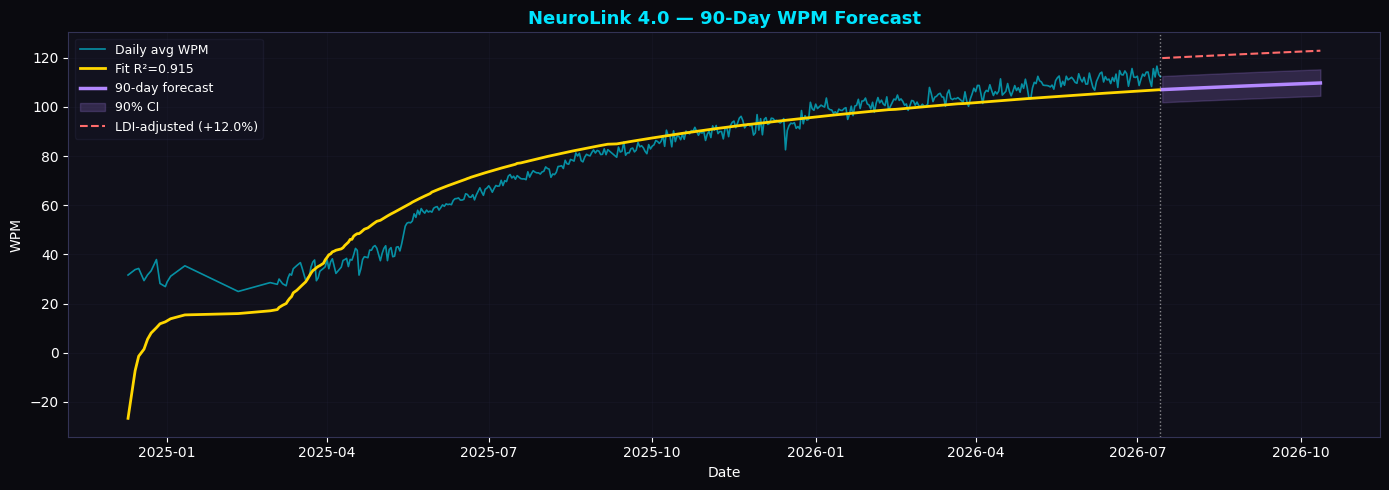

Forecast plot saved -> neurolink_v4_forecast.png


In [ ]:
# Build daily WPM + cumulative lesson count
lesson_counts = eng.df.groupby('date')['wpm'].count().reset_index()
lesson_counts.columns = ['date','n_lessons']
lesson_counts['date'] = pd.to_datetime(lesson_counts['date'])
daily_full = daily.merge(lesson_counts, on='date', how='left').fillna(0)
daily_full['cum_lessons'] = daily_full['n_lessons'].cumsum()

x_data = daily_full['cum_lessons'].values.astype(float)
y_data = daily_full['avg_wpm'].values.astype(float)

# Fit log growth curve
def log_growth(x, a, b):
    return a * np.log1p(x) + b

popt, pcov = curve_fit(log_growth, x_data, y_data, p0=[10, 50], maxfev=10000)
a_fit, b_fit = popt
perr = np.sqrt(np.diag(pcov))
fit_r2 = r2_score(y_data, log_growth(x_data, *popt))

# Current practice rate
daily_rate = float(x_data[-1]) / len(daily_full)
current_lessons = int(x_data[-1])

# 90-day projection
future_x     = np.array([current_lessons + daily_rate*d for d in range(1,91)])
future_dates = pd.date_range(daily_full['date'].max()+pd.Timedelta(days=1), periods=90)
wpm_forecast = log_growth(future_x, *popt)

# Bootstrap confidence band
np.random.seed(SEED)
boot = np.array([log_growth(future_x, np.random.normal(a_fit,perr[0]), np.random.normal(b_fit,perr[1])) for _ in range(2000)])
wpm_lo = np.percentile(boot, 5, axis=0)
wpm_hi = np.percentile(boot, 95, axis=0)

# LDI-adjusted forecast
recent_ldi   = daily['ovr_ldi_7d'].iloc[-7:].mean()
baseline_ldi = thresholds['ovr']['mu']
ldi_ratio    = recent_ldi / (baseline_ldi + 1e-8)
adj_factor   = 1.0 - 0.15*(ldi_ratio - 1.0)
wpm_adj      = wpm_forecast * adj_factor

print('='*62)
print('   NEUROLINK 4.0 — 90-DAY WPM FORECAST')
print('='*62)
print(f'  Learning curve fit R²          : {fit_r2:.4f}')
print(f'  Fit: WPM = {a_fit:.3f} × log1p(lessons) + {b_fit:.3f}')
print(f'  Avg lessons / day              : {daily_rate:.0f}')
print(f'  Current avg WPM (last 7 days)  : {y_data[-7:].mean():.1f}')
print()
print(f'  Forecast at +30 days  : {wpm_forecast[29]:.1f} WPM  90% CI [{wpm_lo[29]:.1f}, {wpm_hi[29]:.1f}]')
print(f'  Forecast at +60 days  : {wpm_forecast[59]:.1f} WPM  90% CI [{wpm_lo[59]:.1f}, {wpm_hi[59]:.1f}]')
print(f'  Forecast at +90 days  : {wpm_forecast[89]:.1f} WPM  90% CI [{wpm_lo[89]:.1f}, {wpm_hi[89]:.1f}]')
print()
print(f'  LDI adjustment                 : {(adj_factor-1)*100:+.1f}%')
print(f'  LDI-adjusted 90-day forecast   : {wpm_adj[89]:.1f} WPM')
print('='*62)

# Plot forecast
fig, ax = plt.subplots(figsize=(14,5), facecolor='#0a0a0f')
ax.set_facecolor('#10101a')
ax.plot(daily_full['date'], y_data, color='#00e5ff', lw=1.2, alpha=0.6, label='Daily avg WPM')
ax.plot(daily_full['date'], log_growth(x_data,*popt), color='#ffd700', lw=2, label=f'Fit R²={fit_r2:.3f}')
ax.plot(future_dates, wpm_forecast, color='#b388ff', lw=2.5, label='90-day forecast')
ax.fill_between(future_dates, wpm_lo, wpm_hi, alpha=0.2, color='#b388ff', label='90% CI')
ax.plot(future_dates, wpm_adj, color='#ff6b6b', lw=1.5, ls='--', label=f'LDI-adjusted ({(adj_factor-1)*100:+.1f}%)')
ax.axvline(daily_full['date'].max(), color='#ffffff', ls=':', lw=1, alpha=0.5)
ax.set_title('NeuroLink 4.0 — 90-Day WPM Forecast', color='#00e5ff', fontsize=13, fontweight='bold')
ax.set_xlabel('Date', color='white'); ax.set_ylabel('WPM', color='white')
ax.tick_params(colors='white'); ax.grid(alpha=0.12, color='#333355')
for sp in ax.spines.values(): sp.set_color('#333355')
ax.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor='white', fontsize=9)
plt.tight_layout()
plt.savefig('neurolink_v4_forecast.png', dpi=120, bbox_inches='tight', facecolor='#0a0a0f')
plt.show()
print('Forecast plot saved -> neurolink_v4_forecast.png')

## 9. Dashboard

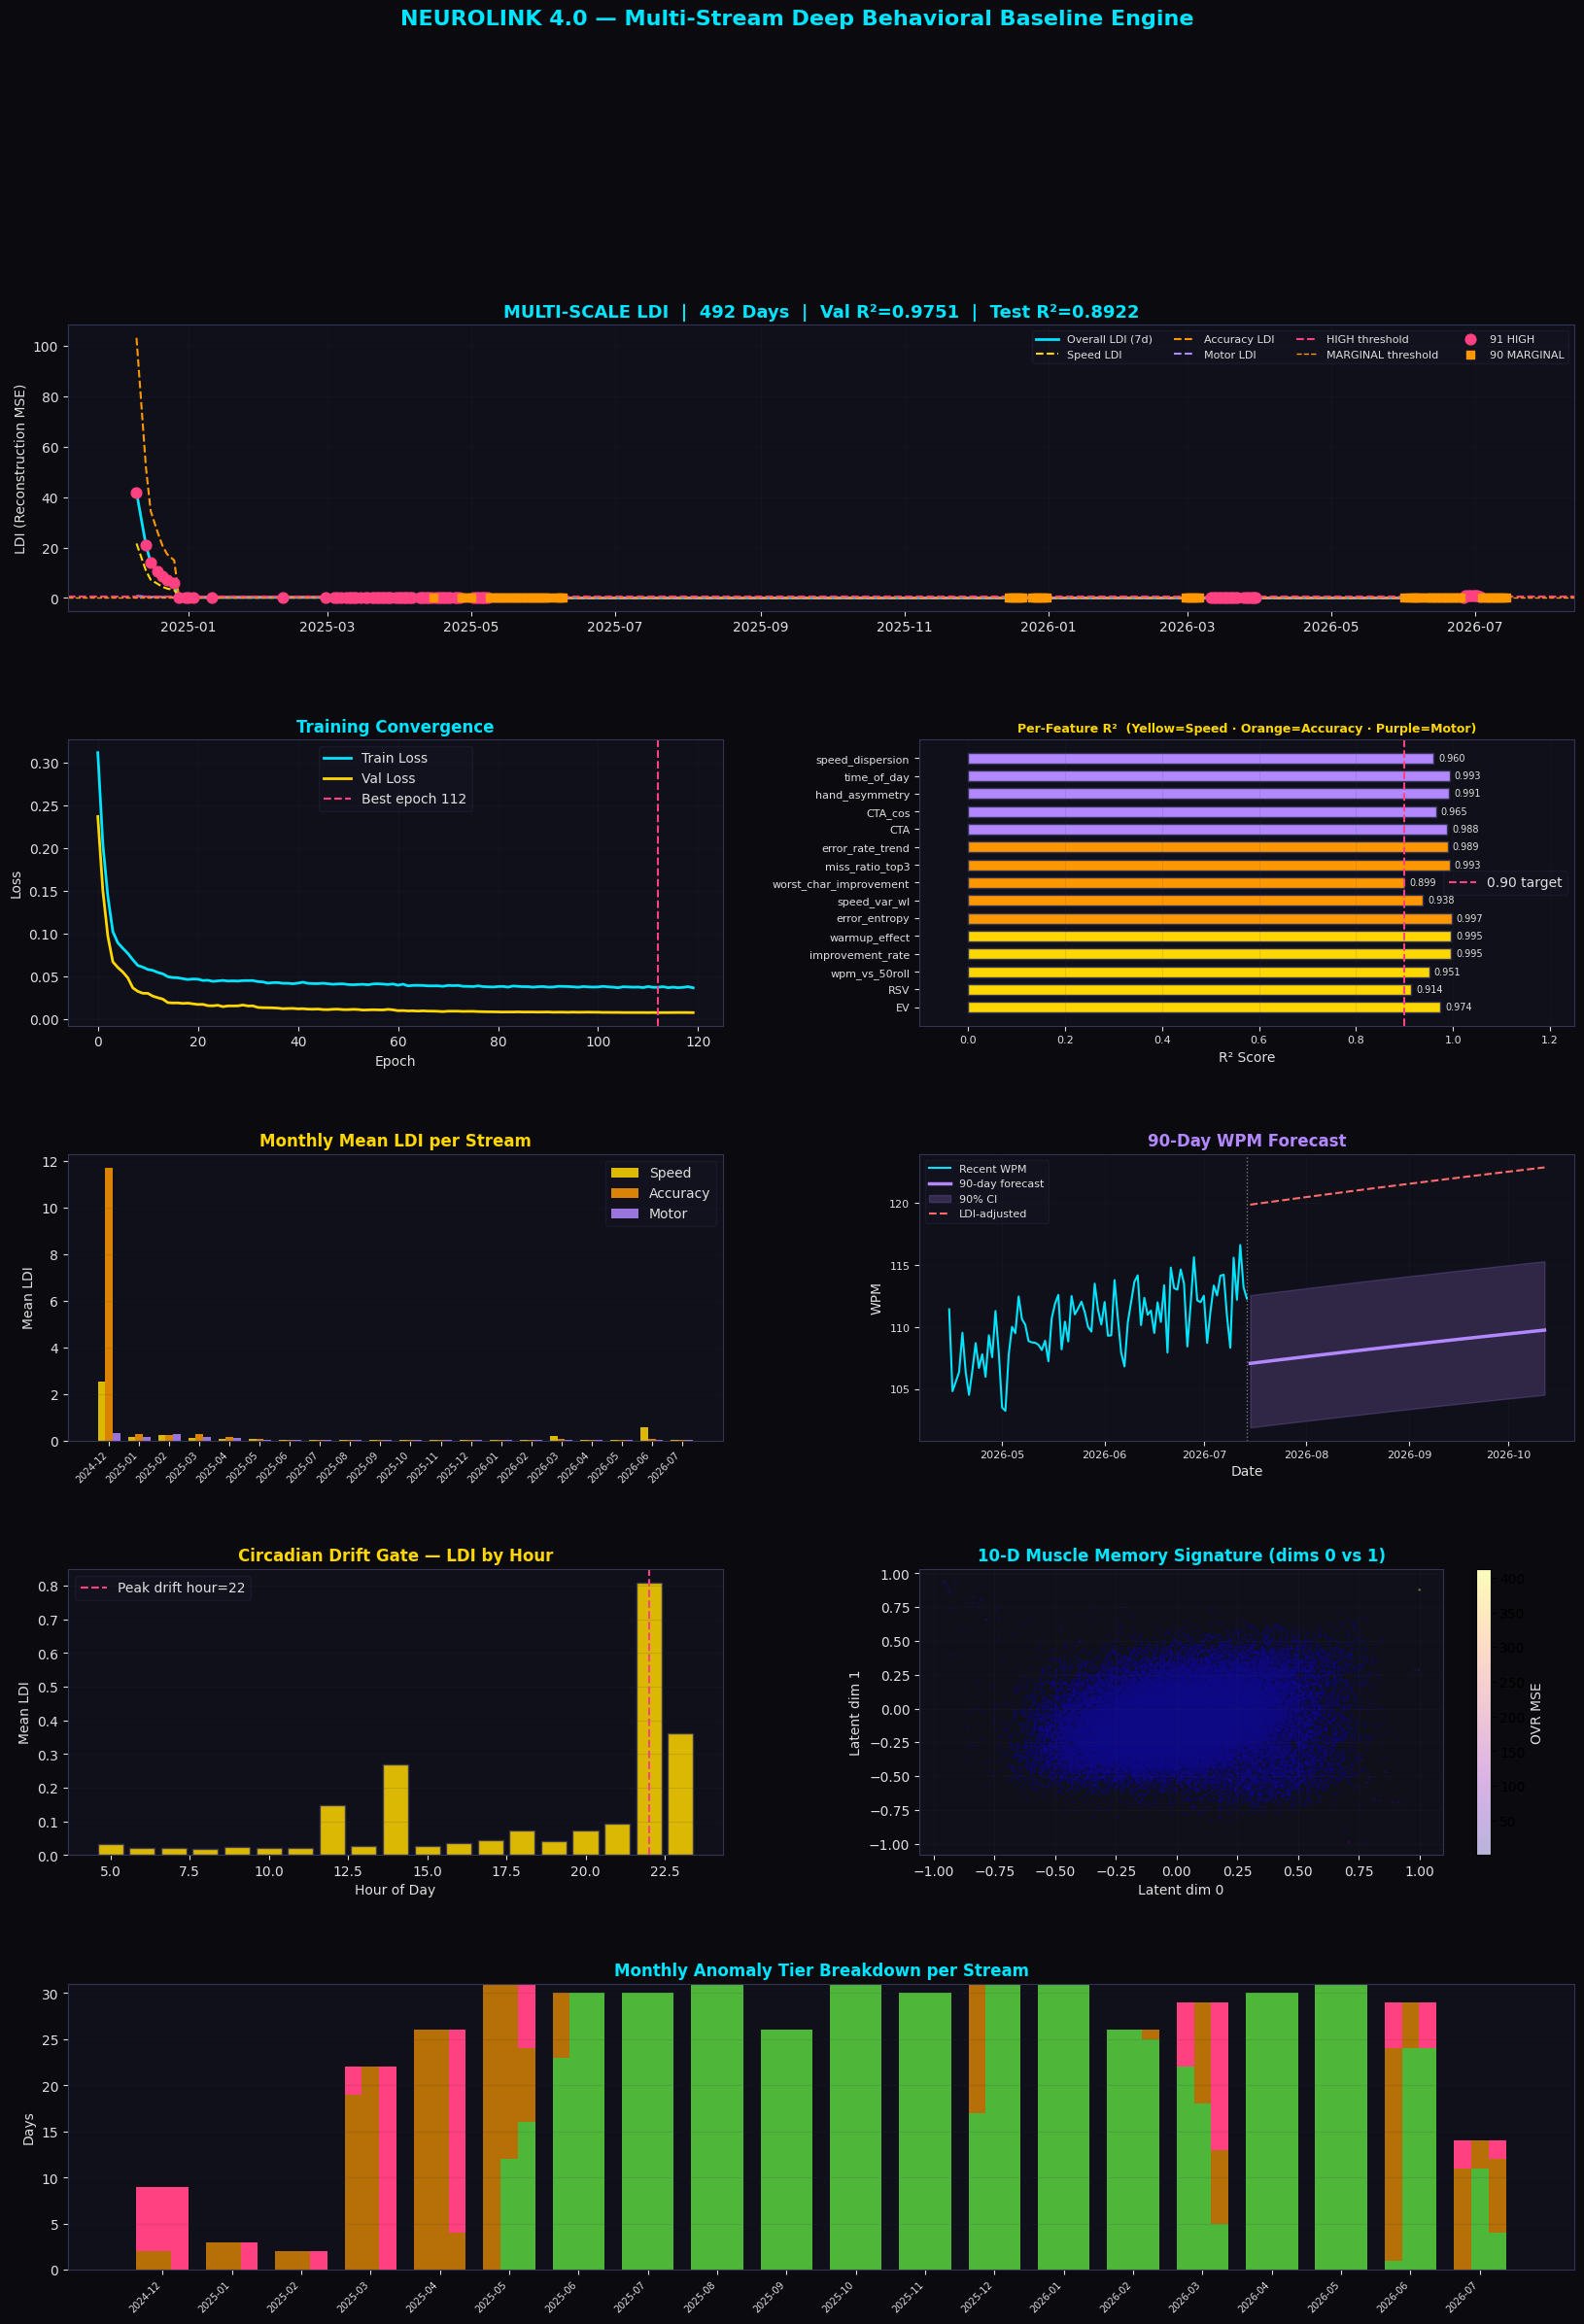

Dashboard saved -> neurolink_v4_dashboard.png


In [ ]:
C_BG     = '#0a0a0f'; C_PANEL = '#10101a'
C_CYAN   = '#00e5ff'; C_YELLOW= '#ffd700'
C_PURPLE = '#b388ff'; C_MAGENTA='#ff4081'
C_ORANGE = '#ff9800'; C_WHITE  = '#e0e0e0'
C_GREEN  = '#69ff47'; C_RED    = '#ff6b6b'

fig = plt.figure(figsize=(20, 26), facecolor=C_BG)
gs  = gridspec.GridSpec(5, 2, figure=fig, hspace=0.45, wspace=0.3)

# Panel 1: Multi-scale LDI timeline
ax1 = fig.add_subplot(gs[0,:])
ax1.set_facecolor(C_PANEL)
ax1.plot(daily['date'], daily['ovr_ldi_7d'], color=C_CYAN,   lw=2,   label='Overall LDI (7d)')
ax1.plot(daily['date'], daily['spd_ldi_7d'], color=C_YELLOW, lw=1.5, ls='--', label='Speed LDI')
ax1.plot(daily['date'], daily['acc_ldi_7d'], color=C_ORANGE, lw=1.5, ls='--', label='Accuracy LDI')
ax1.plot(daily['date'], daily['mot_ldi_7d'], color=C_PURPLE, lw=1.5, ls='--', label='Motor LDI')
ax1.axhline(thresholds['ovr']['hi'], color=C_MAGENTA, ls='--', lw=1.5, label=f'HIGH threshold')
ax1.axhline(thresholds['ovr']['lo'], color=C_ORANGE,  ls='--', lw=1.0, label=f'MARGINAL threshold')
high_d = daily[daily['combined_tier']=='HIGH']
marg_d = daily[daily['combined_tier']=='MARGINAL']
ax1.scatter(high_d['date'], high_d['ovr_ldi_7d'], color=C_MAGENTA, s=60, zorder=6, label=f'{len(high_d)} HIGH')
ax1.scatter(marg_d['date'], marg_d['ovr_ldi_7d'], color=C_ORANGE,  s=40, zorder=6, marker='s', label=f'{len(marg_d)} MARGINAL')
ax1.set_title(f'MULTI-SCALE LDI  |  {len(daily)} Days  |  Val R²={r2_val:.4f}  |  Test R²={r2_test:.4f}',
              color=C_CYAN, fontsize=13, fontweight='bold')
ax1.set_ylabel('LDI (Reconstruction MSE)', color=C_WHITE)
ax1.tick_params(colors=C_WHITE); ax1.grid(alpha=0.12, color='#333355')
for sp in ax1.spines.values(): sp.set_color('#333355')
ax1.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=8, ncol=4)

# Panel 2: Training convergence
ax2 = fig.add_subplot(gs[1,0])
ax2.set_facecolor(C_PANEL)
ax2.plot(train_losses, color=C_CYAN,   lw=2, label='Train Loss')
ax2.plot(val_losses,   color=C_YELLOW, lw=2, label='Val Loss')
ax2.axvline(best_epoch, color=C_MAGENTA, ls='--', lw=1.5, label=f'Best epoch {best_epoch}')
ax2.set_title('Training Convergence', color=C_CYAN, fontweight='bold')
ax2.set_xlabel('Epoch', color=C_WHITE); ax2.set_ylabel('Loss', color=C_WHITE)
ax2.tick_params(colors=C_WHITE); ax2.grid(alpha=0.12, color='#333355')
for sp in ax2.spines.values(): sp.set_color('#333355')
ax2.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# Panel 3: Per-feature R²
ax3 = fig.add_subplot(gs[1,1])
ax3.set_facecolor(C_PANEL)
labels = list(per_r2.keys())
vals   = list(per_r2.values())
colors = []
for i,col in enumerate(labels):
    if i in SPEED_IDX:    colors.append(C_YELLOW)
    elif i in ACCURACY_IDX: colors.append(C_ORANGE)
    else:                  colors.append(C_PURPLE)
bars = ax3.barh(labels, vals, color=colors, edgecolor='#333355', height=0.6)
ax3.axvline(0.90, color=C_MAGENTA, ls='--', lw=1.5, label='0.90 target')
for bar, val in zip(bars, vals):
    ax3.text(max(val,0)+0.01, bar.get_y()+bar.get_height()/2, f'{val:.3f}',
             va='center', ha='left', color=C_WHITE, fontsize=7)
ax3.set_xlim(-0.1, 1.25)
ax3.set_title('Per-Feature R²  (Yellow=Speed · Orange=Accuracy · Purple=Motor)', color=C_YELLOW, fontweight='bold', fontsize=9)
ax3.set_xlabel('R² Score', color=C_WHITE)
ax3.tick_params(colors=C_WHITE, labelsize=8); ax3.grid(alpha=0.12, color='#333355', axis='x')
for sp in ax3.spines.values(): sp.set_color('#333355')
ax3.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# Panel 4: Stream LDI comparison (monthly)
ax4 = fig.add_subplot(gs[2,0])
ax4.set_facecolor(C_PANEL)
daily['month'] = daily['date'].dt.to_period('M')
monthly = daily.groupby('month')[['spd_ldi','acc_ldi','mot_ldi']].mean()
x_m = np.arange(len(monthly)); w = 0.25
ax4.bar(x_m-w, monthly['spd_ldi'], width=w, color=C_YELLOW, label='Speed', alpha=0.85)
ax4.bar(x_m,   monthly['acc_ldi'], width=w, color=C_ORANGE, label='Accuracy', alpha=0.85)
ax4.bar(x_m+w, monthly['mot_ldi'], width=w, color=C_PURPLE, label='Motor', alpha=0.85)
ax4.set_xticks(x_m); ax4.set_xticklabels([str(p) for p in monthly.index], rotation=45, ha='right', fontsize=7)
ax4.set_title('Monthly Mean LDI per Stream', color=C_YELLOW, fontweight='bold')
ax4.set_ylabel('Mean LDI', color=C_WHITE)
ax4.tick_params(colors=C_WHITE); ax4.grid(alpha=0.12, color='#333355', axis='y')
for sp in ax4.spines.values(): sp.set_color('#333355')
ax4.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# Panel 5: 90-day forecast
ax5 = fig.add_subplot(gs[2,1])
ax5.set_facecolor(C_PANEL)
recent = daily_full.tail(90)
ax5.plot(recent['date'], recent['avg_wpm'], color=C_CYAN, lw=1.5, label='Recent WPM')
ax5.plot(future_dates, wpm_forecast, color=C_PURPLE, lw=2.5, label='90-day forecast')
ax5.fill_between(future_dates, wpm_lo, wpm_hi, alpha=0.2, color=C_PURPLE, label='90% CI')
ax5.plot(future_dates, wpm_adj, color=C_RED, lw=1.5, ls='--', label='LDI-adjusted')
ax5.axvline(daily_full['date'].max(), color=C_WHITE, ls=':', lw=1, alpha=0.5)
ax5.set_title('90-Day WPM Forecast', color=C_PURPLE, fontweight='bold')
ax5.set_xlabel('Date', color=C_WHITE); ax5.set_ylabel('WPM', color=C_WHITE)
ax5.tick_params(colors=C_WHITE, labelsize=8); ax5.grid(alpha=0.12, color='#333355')
for sp in ax5.spines.values(): sp.set_color('#333355')
ax5.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE, fontsize=8)

# Panel 6: Circadian LDI
ax6 = fig.add_subplot(gs[3,0])
ax6.set_facecolor(C_PANEL)
hourly = pd.DataFrame({'hour': pd.to_datetime(eng.timestamps).dt.hour, 'ovr': ovr_mse})
hm = hourly.groupby('hour')['ovr'].mean()
ax6.bar(hm.index, hm.values, color=C_YELLOW, alpha=0.85, edgecolor='#333355')
peak_h = int(hm.idxmax())
ax6.axvline(peak_h, color=C_MAGENTA, ls='--', lw=1.5, label=f'Peak drift hour={peak_h}')
ax6.set_title('Circadian Drift Gate — LDI by Hour', color=C_YELLOW, fontweight='bold')
ax6.set_xlabel('Hour of Day', color=C_WHITE); ax6.set_ylabel('Mean LDI', color=C_WHITE)
ax6.tick_params(colors=C_WHITE); ax6.grid(alpha=0.12, color='#333355', axis='y')
for sp in ax6.spines.values(): sp.set_color('#333355')
ax6.legend(framealpha=0.25, facecolor='#1a1a2e', edgecolor='#333355', labelcolor=C_WHITE)

# Panel 7: Latent space
ax7 = fig.add_subplot(gs[3,1])
ax7.set_facecolor(C_PANEL)
with torch.no_grad():
    latent = base_model.encode(X_full_t).cpu().numpy()
sc = ax7.scatter(latent[:,0], latent[:,1], c=ovr_mse, cmap='plasma', s=1, alpha=0.3)
plt.colorbar(sc, ax=ax7, label='OVR MSE').ax.yaxis.label.set_color(C_WHITE)
ax7.set_title('10-D Muscle Memory Signature (dims 0 vs 1)', color=C_CYAN, fontweight='bold')
ax7.set_xlabel('Latent dim 0', color=C_WHITE); ax7.set_ylabel('Latent dim 1', color=C_WHITE)
ax7.tick_params(colors=C_WHITE); ax7.grid(alpha=0.12, color='#333355')
for sp in ax7.spines.values(): sp.set_color('#333355')

# Panel 8: Tier breakdown per stream (stacked bar)
ax8 = fig.add_subplot(gs[4,:])
ax8.set_facecolor(C_PANEL)
months = daily['month'].unique()
tier_colors = {'HIGH':C_MAGENTA,'MARGINAL':C_ORANGE,'NORMAL':C_GREEN}
bottom_spd = np.zeros(len(months)); bottom_acc = np.zeros(len(months)); bottom_mot = np.zeros(len(months))
x_pos = np.arange(len(months))
for tier in ['NORMAL','MARGINAL','HIGH']:
    for si, (stream, col) in enumerate([('spd','spd_tier'),('acc','acc_tier'),('mot','mot_tier')]):
        counts = daily.groupby('month')[col].apply(lambda s: (s==tier).sum()).reindex(months, fill_value=0).values
        offset = (si-1)*0.25
        ax8.bar(x_pos+offset, counts, width=0.25,
                color=tier_colors[tier], alpha=0.7 if tier!='HIGH' else 1.0,
                bottom=[bottom_spd,bottom_acc,bottom_mot][si],
                label=f'{tier} ({["Speed","Accuracy","Motor"][si]})' if tier=='HIGH' else None)
        if stream=='spd': bottom_spd += counts
        elif stream=='acc': bottom_acc += counts
        else: bottom_mot += counts
ax8.set_xticks(x_pos); ax8.set_xticklabels([str(p) for p in months], rotation=45, ha='right', fontsize=7)
ax8.set_title('Monthly Anomaly Tier Breakdown per Stream', color=C_CYAN, fontweight='bold')
ax8.set_ylabel('Days', color=C_WHITE)
ax8.tick_params(colors=C_WHITE); ax8.grid(alpha=0.12, color='#333355', axis='y')
for sp in ax8.spines.values(): sp.set_color('#333355')

fig.suptitle('NEUROLINK 4.0 — Multi-Stream Deep Behavioral Baseline Engine',
             color=C_CYAN, fontsize=16, fontweight='bold', y=1.005)
plt.savefig('neurolink_v4_dashboard.png', dpi=120, bbox_inches='tight', facecolor=C_BG)
plt.show()
print('Dashboard saved -> neurolink_v4_dashboard.png')

## 10. Real-Time Inference Engine

In [ ]:
class NeuroLink4Inference:
    """Real-time per-lesson inference with 3-stream decomposed alerting."""
    def __init__(self, model, scaler, thresholds, feature_cols):
        self.model = model; self.scaler = scaler
        self.thresholds = thresholds; self.feature_cols = feature_cols

    def infer(self, raw_features: np.ndarray) -> dict:
        x_sc = self.scaler.transform(raw_features.reshape(1,-1)).astype(np.float32)
        x_t  = torch.tensor(x_sc, device=device)
        self.model.eval()
        with torch.no_grad():
            sr, ar, mr = self.model(x_t)
        x_np = x_sc[0]
        spd_mse = float(((sr.cpu().numpy()[0] - x_np[SPEED_IDX   ])**2).mean())
        acc_mse = float(((ar.cpu().numpy()[0] - x_np[ACCURACY_IDX])**2).mean())
        mot_mse = float(((mr.cpu().numpy()[0] - x_np[MOTOR_IDX   ])**2).mean())
        ovr_mse = (spd_mse + acc_mse + mot_mse) / 3.0

        def tier(v, key):
            t = self.thresholds[key]
            return 'HIGH' if v>=t['hi'] else ('MARGINAL' if v>=t['lo'] else 'NORMAL')

        tier_order = {'HIGH':2,'MARGINAL':1,'NORMAL':0}
        spd_t = tier(spd_mse,'spd'); acc_t = tier(acc_mse,'acc'); mot_t = tier(mot_mse,'mot')
        combined = max([spd_t,acc_t,mot_t], key=lambda t: tier_order[t])
        emoji = {'HIGH':'🔴','MARGINAL':'🟡','NORMAL':'🟢'}[combined]

        # Top drivers (per full feature)
        recon = np.zeros(INPUT_DIM)
        recon[SPEED_IDX]    = sr.cpu().numpy()[0]
        recon[ACCURACY_IDX] = ar.cpu().numpy()[0]
        recon[MOTOR_IDX]    = mr.cpu().numpy()[0]
        errs = (recon - x_np)**2
        top3 = sorted(enumerate(errs), key=lambda x:-x[1])[:3]
        drivers = [(self.feature_cols[i], 100*e/sum(errs)) for i,e in top3]

        return {'ovr_mse':ovr_mse,'spd_mse':spd_mse,'acc_mse':acc_mse,'mot_mse':mot_mse,
                'combined_tier':combined,'spd_tier':spd_t,'acc_tier':acc_t,'mot_tier':mot_t,
                'emoji':emoji,'top_drivers':drivers}


inference_engine = NeuroLink4Inference(base_model, scaler, thresholds, NeuroLink4Engine.FEATURE_COLS)

print('Real-time inference demo — last 10 lessons:')
print('-'*80)
for i in range(-10, 0):
    feat = eng.features[i]
    r    = inference_engine.infer(feat)
    drivers_str = '  |  '.join([f'{n} {p:.0f}%' for n,p in r['top_drivers']])
    print(f'  Lesson {i:>3}  OVR={r["ovr_mse"]:.5f}  {r["emoji"]} {r["combined_tier"]:8}  '
          f'[Spd:{r["spd_tier"]:8} Acc:{r["acc_tier"]:8} Mot:{r["mot_tier"]:8}]')
    print(f'           Drivers: {drivers_str}')
print('-'*80)

Real-time inference demo — last 10 lessons:
--------------------------------------------------------------------------------
  Lesson -10  OVR=0.01343  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: wpm_vs_50roll 18%  |  CTA 17%  |  speed_dispersion 15%
  Lesson  -9  OVR=0.01001  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: wpm_vs_50roll 31%  |  CTA 22%  |  worst_char_improvement 12%
  Lesson  -8  OVR=0.00734  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: CTA 42%  |  RSV 23%  |  time_of_day 14%
  Lesson  -7  OVR=0.00860  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: CTA 32%  |  RSV 19%  |  speed_dispersion 14%
  Lesson  -6  OVR=0.01483  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: worst_char_improvement 26%  |  RSV 20%  |  wpm_vs_50roll 14%
  Lesson  -5  OVR=0.01669  🟢 NORMAL    [Spd:NORMAL   Acc:NORMAL   Mot:NORMAL  ]
           Drivers: speed_dispers

## 11. Clinical Report & Model Save

In [ ]:
import pickle

print('='*68)
print('   NEUROLINK 4.0  --  BEHAVIORAL BASELINE REPORT')
print('='*68)
print(f'  Dataset          : {len(eng.df):,} lessons')
print(f'  Date range       : {eng.timestamps.min().date()} -> {eng.timestamps.max().date()}')
print(f'  Features         : {INPUT_DIM} (5 Speed + 6 Accuracy + 7 Motor)')
print(f'  Val R2 (weighted): {r2_val:.4f}  {"PASS" if r2_val>=0.90 else "FAIL"}')
print(f'  Test R2          : {r2_test:.4f}')
print(f'  Best epoch       : {best_epoch}  (val={best_val_loss:.5f})')
print(f'  DP budget        : ε={final_epsilon:.4f}, δ={TARGET_DELTA}')
print('-'*68)
print('  MULTI-SCALE LDI BASELINES')
for key, name in {'spd':'Speed','acc':'Accuracy','mot':'Motor','ovr':'Overall'}.items():
    t = thresholds[key]
    print(f'  {name:10}  μ={t["mu"]:.5f}  CI=[{t["lo"]:.5f}, {t["hi"]:.5f}]')
print('-'*68)
print('  ANOMALY DETECTION (combined — worst of 3 streams)')
for tier in ['HIGH','MARGINAL','NORMAL']:
    n = (daily['combined_tier']==tier).sum()
    print(f'  {tier:8} : {n:3d} / {len(daily)} ({100*n/len(daily):.1f}%)')
print('-'*68)
print('  90-DAY WPM FORECAST')
print(f'  Current avg WPM  : {y_data[-7:].mean():.1f}')
print(f'  +30 days         : {wpm_forecast[29]:.1f}  [{wpm_lo[29]:.1f}, {wpm_hi[29]:.1f}]')
print(f'  +60 days         : {wpm_forecast[59]:.1f}  [{wpm_lo[59]:.1f}, {wpm_hi[59]:.1f}]')
print(f'  +90 days         : {wpm_forecast[89]:.1f}  [{wpm_lo[89]:.1f}, {wpm_hi[89]:.1f}]')
print(f'  LDI-adjusted +90 : {wpm_adj[89]:.1f}')
print('-'*68)
print('  PER-FEATURE R²')
for col, r2 in per_r2.items():
    i = NeuroLink4Engine.FEATURE_COLS.index(col)
    stream = 'SPD' if i in SPEED_IDX else ('ACC' if i in ACCURACY_IDX else 'MOT')
    tag = ' [NEW]' if col in {'miss_ratio_top3','error_rate_trend','speed_dispersion'} else ''
    print(f'  [{stream}] {col:<25} R²={r2:.3f}{tag}')
print('='*68)

torch.save({
    'model_state_dict' : base_model.state_dict(),
    'input_dim'        : INPUT_DIM,
    'feature_cols'     : NeuroLink4Engine.FEATURE_COLS,
    'speed_idx'        : SPEED_IDX,
    'accuracy_idx'     : ACCURACY_IDX,
    'motor_idx'        : MOTOR_IDX,
    'r2_val'           : r2_val,
    'r2_test'          : r2_test,
    'thresholds'       : thresholds,
    'best_epoch'       : best_epoch,
    'per_feature_r2'   : per_r2,
    'seed'             : SEED,
    'final_epsilon'    : final_epsilon,
    'n_lessons'        : len(eng.df),
    'forecast_params'  : {'a':float(a_fit),'b':float(b_fit),'daily_rate':daily_rate},
    'forecast_90d'     : {'wpm':wpm_forecast.tolist(),'lo':wpm_lo.tolist(),'hi':wpm_hi.tolist()},
}, 'neurolink_v4_model.pt')

with open('neurolink_v4_scaler.pkl','wb') as f:
    pickle.dump(scaler, f)

print('Model  saved -> neurolink_v4_model.pt')
print('Scaler saved -> neurolink_v4_scaler.pkl')

   NEUROLINK 4.0  --  BEHAVIORAL BASELINE REPORT
  Dataset          : 50,321 lessons
  Date range       : 2024-12-10 -> 2026-07-14
  Features         : 15 (5 Speed + 6 Accuracy + 7 Motor)
  Val R2 (weighted): 0.9751  PASS
  Test R2          : 0.8922
  Best epoch       : 112  (val=0.00788)
  DP budget        : ε=9.9966, δ=1e-05
--------------------------------------------------------------------
  MULTI-SCALE LDI BASELINES
  Speed       μ=0.10485  CI=[0.03515, 0.22688]
  Accuracy    μ=0.31835  CI=[0.04860, 0.84876]
  Motor       μ=0.03553  CI=[0.02884, 0.04294]
  Overall     μ=0.15291  CI=[0.03931, 0.37034]
--------------------------------------------------------------------
  ANOMALY DETECTION (combined — worst of 3 streams)
  HIGH     :  91 / 492 (18.5%)
  MARGINAL :  90 / 492 (18.3%)
  NORMAL   : 311 / 492 (63.2%)
--------------------------------------------------------------------
  90-DAY WPM FORECAST
  Current avg WPM  : 112.7
  +30 days         : 108.0  [102.8, 113.5]
  +60 days 